In [154]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler

# Load labelled data
df = pd.read_csv("../data/processed/kerala_flood_labeled.csv")

months = [
    "JAN", "FEB", "MAR", "APR", "MAY", "JUN",
    "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"
]

cutoffs = {
    "March": months[:3],
    "May": months[:5],
    "June": months[:6],
    "July": months[:7],
    "September": months[:9]
}

y = df["FLOOD_LABEL"]

# Define the five required classifiers
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=3, min_samples_leaf=2, random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5, weights="distance"
    ),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(
        kernel="rbf", C=1.0, random_state=42
    )
}

# Three-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=42
)

results = []
prediction_records = []
fold_metrics_records = []

for cutoff, columns in cutoffs.items():

    X = df[columns]

    for model_name, estimator in models.items():

        oof_predictions = np.zeros(len(df), dtype=int)
        oof_scores = np.zeros(len(df))
        oof_folds = np.zeros(len(df), dtype=int)

        for fold_number, (train_idx, val_idx) in enumerate(
            cv.split(X, y), start=1
        ):

            pipeline = Pipeline([
                ("scaler", StandardScaler()),
                ("oversampler", RandomOverSampler(random_state=42)),
                ("classifier", estimator)
            ])

            pipeline.fit(X.iloc[train_idx], y.iloc[train_idx])

            oof_predictions[val_idx] = pipeline.predict(
                X.iloc[val_idx]
            )

            if model_name == "SVM":

                # SVM decision_function returns ranking scores,
                # not calibrated probabilities.

                oof_scores[val_idx] = pipeline.decision_function(
                    X.iloc[val_idx]
                )
            else:

                # Other classifiers return positive-class probabilities.

                oof_scores[val_idx] = pipeline.predict_proba(
                    X.iloc[val_idx]
                )[:, 1]

            # Store the validation fold for each observation
            oof_folds[val_idx] = fold_number

            # Evaluate this individual validation fold
            fold_y_true = y.iloc[val_idx]
            fold_y_pred = oof_predictions[val_idx]
            fold_scores = oof_scores[val_idx]

            tn, fp, fn, tp = confusion_matrix(
                fold_y_true,
                fold_y_pred,
                labels=[0, 1]
            ).ravel()

            fold_metrics_records.append({
                "Warning Window": cutoff,
                "Model": model_name,
                "Fold": fold_number,
                "Validation Years": ", ".join(
                    map(str, df.iloc[val_idx]["YEAR"].tolist())
                ),
                "TP": tp,
                "FN": fn,
                "FP": fp,
                "TN": tn,
                "Recall": recall_score(
                    fold_y_true, fold_y_pred, zero_division=0
                ),
                "Precision": precision_score(
                    fold_y_true, fold_y_pred, zero_division=0
                ),
                "F1 Score": f1_score(
                    fold_y_true, fold_y_pred, zero_division=0
                ),
                "ROC-AUC": roc_auc_score(
                    fold_y_true, fold_scores
                ),
                "PR-AUC (Average Precision)": average_precision_score(
                    fold_y_true, fold_scores
                )
            })

        results.append({
            "Warning Window": cutoff,
            "Model": model_name,
            "Recall": recall_score(y, oof_predictions, zero_division=0),
            "F1 Score": f1_score(y, oof_predictions, zero_division=0),
            "ROC-AUC": roc_auc_score(y, oof_scores),
            "PR-AUC (Average Precision)": average_precision_score(y, oof_scores)
        })

        prediction_records.append(pd.DataFrame({
            "YEAR": df["YEAR"],
            "CUTOFF": cutoff,
            "MODEL": model_name,
            "FOLD": oof_folds,
            "ACTUAL": y,
            "PREDICTED": oof_predictions,
            "SCORE": oof_scores
        }))

# Create comparison table
results_df = pd.DataFrame(results)

display(
    results_df.round(3).sort_values(
        ["Warning Window", "F1 Score"],
        ascending=[True, False]
    )
)

print("\nModels evaluated:", len(models))
print("Warning windows:", len(cutoffs))
print("Total experiments:", len(results_df))
print("Cross-validation folds:", cv.get_n_splits())

,Warning Window,Model,Recall,F1 Score,ROC-AUC,PR-AUC (Average Precision)
15,July,Logistic Regression,0.500,0.222,0.709,0.247
16,July,Decision Tree,0.333,0.211,0.613,0.078
18,July,Naive Bayes,0.167,0.077,0.476,0.064
17,July,KNN,0.000,0.000,0.419,0.051
19,July,SVM,0.000,0.000,0.446,0.057
10,June,Logistic Regression,0.667,0.296,0.677,0.115
11,June,Decision Tree,0.333,0.174,0.592,0.068
13,June,Naive Bayes,0.167,0.062,0.420,0.052
12,June,KNN,0.000,0.000,0.396,0.051
14,June,SVM,0.000,0.000,0.275,0.039



Models evaluated: 5
Warning windows: 5
Total experiments: 25
Cross-validation folds: 3


In [155]:
# SUPPLEMENTARY EXPERIMENT:
# BASELINE AND IMBALANCE-HANDLING COMPARISON

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler

supplementary_results = []
supplementary_fold_records = []

# Three approaches to compare
comparison_models = {
    "Dummy Classifier": "dummy",
    "Class-Weighted Logistic Regression": "weighted",
    "RandomOverSampler Logistic Regression": "oversampling"
}

for cutoff, columns in cutoffs.items():

    X = df[columns]

    for model_name, approach in comparison_models.items():

        oof_predictions = np.zeros(len(df), dtype=int)
        oof_scores = np.zeros(len(df))

        for fold_number, (train_idx, val_idx) in enumerate(
            cv.split(X, y), start=1
        ):

            X_train = X.iloc[train_idx]
            X_val = X.iloc[val_idx]

            y_train = y.iloc[train_idx]
            y_val = y.iloc[val_idx]

            if approach == "dummy":

                estimator = DummyClassifier(
                    strategy="prior"
                )

            elif approach == "weighted":

                estimator = Pipeline([
                    ("scaler", StandardScaler()),
                    ("classifier", LogisticRegression(
                        max_iter=2000,
                        random_state=42,
                        class_weight="balanced"
                    ))
                ])

            else:

                estimator = Pipeline([
                    ("scaler", StandardScaler()),
                    ("oversampler", RandomOverSampler(
                        random_state=42
                    )),
                    ("classifier", LogisticRegression(
                        max_iter=2000,
                        random_state=42
                    ))
                ])

            estimator.fit(X_train, y_train)

            predictions = estimator.predict(X_val)

            scores = estimator.predict_proba(X_val)[:, 1]

            oof_predictions[val_idx] = predictions
            oof_scores[val_idx] = scores

            # Calculate individual fold metrics
            assert y_val.nunique() == 2, (
                f"Fold {fold_number} contains only one class."
            )

            tn, fp, fn, tp = confusion_matrix(
                y_val,
                predictions,
                labels=[0, 1]
            ).ravel()

            supplementary_fold_records.append({

                "Warning Window": cutoff,
                "Approach": model_name,
                "Fold": fold_number,

                "Validation Observations": len(y_val),
                "Positive Years": int(y_val.sum()),

                "TP": int(tp),
                "FN": int(fn),
                "FP": int(fp),
                "TN": int(tn),

                "Recall": recall_score(
                    y_val, predictions, zero_division=0
                ),

                "Precision": precision_score(
                    y_val, predictions, zero_division=0
                ),

                "F1 Score": f1_score(
                    y_val, predictions, zero_division=0
                ),

                "ROC-AUC": roc_auc_score(
                    y_val, scores
                ),

                "PR-AUC (Average Precision)": average_precision_score(
                    y_val, scores
                )
            })

        # Aggregate out-of-fold classification metrics
        tn, fp, fn, tp = confusion_matrix(
            y,
            oof_predictions,
            labels=[0, 1]
        ).ravel()

        supplementary_results.append({

            "Warning Window": cutoff,
            "Approach": model_name,

            "Recall": recall_score(
                y, oof_predictions, zero_division=0
            ),

            "Precision": precision_score(
                y, oof_predictions, zero_division=0
            ),

            "F1 Score": f1_score(
                y, oof_predictions, zero_division=0
            ),

            "TP": int(tp),
            "FN": int(fn),
            "FP": int(fp),
            "TN": int(tn),

            "Pooled ROC-AUC": roc_auc_score(
                y, oof_scores
            ),

            "Pooled PR-AUC": average_precision_score(
                y, oof_scores
            )
        })

# Create pooled comparison table
supplementary_results_df = pd.DataFrame(
    supplementary_results
)

# Create fold-level evaluation table
supplementary_fold_metrics_df = pd.DataFrame(
    supplementary_fold_records
)

# Calculate fold-wise mean and standard deviation
supplementary_fold_summary_df = (
    supplementary_fold_metrics_df
    .groupby(["Warning Window", "Approach"])
    .agg(
        Recall_Mean=("Recall", "mean"),
        Recall_Std=("Recall", "std"),

        F1_Mean=("F1 Score", "mean"),
        F1_Std=("F1 Score", "std"),

        ROC_AUC_Mean=("ROC-AUC", "mean"),
        ROC_AUC_Std=("ROC-AUC", "std"),

        PR_AUC_Mean=("PR-AUC (Average Precision)", "mean"),
        PR_AUC_Std=("PR-AUC (Average Precision)", "std")
    )
    .reset_index()
    .round(3)
)

# Combine pooled classification and fold-level ranking results
supplementary_results_df = supplementary_results_df.merge(
    supplementary_fold_summary_df,
    on=["Warning Window", "Approach"],
    how="left",
    validate="one_to_one"
)

# Add the random-ranking prevalence reference
supplementary_results_df["PR_AUC_Prevalence_Baseline"] = (
    y.mean()
)

# Validate experimental dimensions
assert len(supplementary_results_df) == 15
assert len(supplementary_fold_metrics_df) == 45
assert len(supplementary_fold_summary_df) == 15

assert supplementary_results_df[
    "ROC_AUC_Mean"
].notna().all()

assert supplementary_results_df[
    "PR_AUC_Mean"
].notna().all()

# Display final results
display(
    supplementary_results_df.round(3).sort_values(
        ["Warning Window", "Approach"]
    )
)

# Save all outputs
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

supplementary_results_df.to_csv(
    output_dir / "supplementary_baseline_comparison.csv",
    index=False
)

supplementary_fold_metrics_df.to_csv(
    output_dir / "supplementary_fold_metrics.csv",
    index=False
)

supplementary_fold_summary_df.to_csv(
    output_dir / "supplementary_fold_summary.csv",
    index=False
)

print("\nBaseline and imbalance comparison completed!")
print("Pooled experiments:", len(supplementary_results_df))
print("Fold-level evaluations:", len(supplementary_fold_metrics_df))
print("Fold summaries:", len(supplementary_fold_summary_df))
print("Random-ranking baseline:", round(y.mean(), 4))
print("All supplementary outputs saved successfully!")

,Warning Window,Approach,Recall,Precision,F1 Score,TP,FN,FP,TN,Pooled ROC-AUC,Pooled PR-AUC,Recall_Mean,Recall_Std,F1_Mean,F1_Std,ROC_AUC_Mean,ROC_AUC_Std,PR_AUC_Mean,PR_AUC_Std,PR_AUC_Prevalence_Baseline
10,July,Class-Weighted Logistic Regression,0.500,0.150,0.231,3,3,17,94,0.730,0.257,0.500,0.500,0.185,0.202,0.793,0.202,0.311,0.201,0.051
9,July,Dummy Classifier,0.000,0.000,0.000,0,6,0,111,0.500,0.051,0.000,0.000,0.000,0.000,0.500,0.000,0.051,0.000,0.051
11,July,RandomOverSampler Logistic Regression,0.500,0.143,0.222,3,3,18,93,0.709,0.247,0.500,0.500,0.172,0.183,0.766,0.199,0.272,0.155,0.051
7,June,Class-Weighted Logistic Regression,0.667,0.182,0.286,4,2,18,93,0.679,0.116,0.667,0.577,0.274,0.286,0.703,0.243,0.202,0.188,0.051
6,June,Dummy Classifier,0.000,0.000,0.000,0,6,0,111,0.500,0.051,0.000,0.000,0.000,0.000,0.500,0.000,0.051,0.000,0.051
8,June,RandomOverSampler Logistic Regression,0.667,0.190,0.296,4,2,17,94,0.677,0.115,0.667,0.577,0.274,0.286,0.707,0.237,0.202,0.188,0.051
1,March,Class-Weighted Logistic Regression,0.333,0.043,0.075,2,4,45,66,0.362,0.046,0.333,0.289,0.074,0.064,0.378,0.204,0.067,0.020,0.051
0,March,Dummy Classifier,0.000,0.000,0.000,0,6,0,111,0.500,0.051,0.000,0.000,0.000,0.000,0.500,0.000,0.051,0.000,0.051
2,March,RandomOverSampler Logistic Regression,0.333,0.043,0.077,2,4,44,67,0.377,0.048,0.333,0.289,0.070,0.061,0.383,0.205,0.068,0.019,0.051
4,May,Class-Weighted Logistic Regression,0.000,0.000,0.000,0,6,42,69,0.243,0.038,0.000,0.000,0.000,0.000,0.243,0.115,0.052,0.009,0.051



Baseline and imbalance comparison completed!
Pooled experiments: 15
Fold-level evaluations: 45
Fold summaries: 15
Random-ranking baseline: 0.0513
All supplementary outputs saved successfully!


In [156]:
# THRESHOLD SENSITIVITY ANALYSIS
# Pooled and Fold-Level Evaluation

threshold_values = [0.25, 0.35, 0.50, 0.65, 0.75]

approaches = [
    "Class-Weighted",
    "RandomOverSampler"
]

threshold_predictions = []
threshold_fold_records = []

for cutoff, columns in cutoffs.items():

    X = df[columns]

    for approach in approaches:

        oof_scores = np.zeros(len(df))
        oof_folds = np.zeros(len(df), dtype=int)

        # Generate out-of-fold scores
        for fold_number, (train_idx, val_idx) in enumerate(
            cv.split(X, y), start=1
        ):

            if approach == "Class-Weighted":

                estimator = Pipeline([
                    ("scaler", StandardScaler()),
                    ("classifier", LogisticRegression(
                        max_iter=2000,
                        random_state=42,
                        class_weight="balanced"
                    ))
                ])

            else:

                estimator = Pipeline([
                    ("scaler", StandardScaler()),
                    ("oversampler", RandomOverSampler(
                        random_state=42
                    )),
                    ("classifier", LogisticRegression(
                        max_iter=2000,
                        random_state=42
                    ))
                ])

            estimator.fit(
                X.iloc[train_idx],
                y.iloc[train_idx]
            )

            oof_scores[val_idx] = estimator.predict_proba(
                X.iloc[val_idx]
            )[:, 1]

            oof_folds[val_idx] = fold_number

        # Evaluate each predefined threshold
        for threshold in threshold_values:

            predictions = (
                oof_scores >= threshold
            ).astype(int)

            # Pooled out-of-fold metrics
            tn, fp, fn, tp = confusion_matrix(
                y,
                predictions,
                labels=[0, 1]
            ).ravel()

            threshold_predictions.append({

                "Warning Window": cutoff,
                "Approach": approach,
                "Threshold": threshold,

                "Recall": recall_score(
                    y, predictions, zero_division=0
                ),

                "Precision": precision_score(
                    y, predictions, zero_division=0
                ),

                "F1 Score": f1_score(
                    y, predictions, zero_division=0
                ),

                "TP": int(tp),
                "FP": int(fp),
                "FN": int(fn),
                "TN": int(tn)
            })

            # Calculate individual fold metrics
            for fold_number in range(1, cv.get_n_splits() + 1):

                fold_mask = oof_folds == fold_number

                fold_y = y.iloc[
                    np.where(fold_mask)[0]
                ]

                fold_predictions = predictions[fold_mask]

                tn_f, fp_f, fn_f, tp_f = confusion_matrix(
                    fold_y,
                    fold_predictions,
                    labels=[0, 1]
                ).ravel()

                threshold_fold_records.append({

                    "Warning Window": cutoff,
                    "Approach": approach,
                    "Threshold": threshold,
                    "Fold": fold_number,

                    "Validation Observations": len(fold_y),
                    "Positive Years": int(fold_y.sum()),

                    "Recall": recall_score(
                        fold_y,
                        fold_predictions,
                        zero_division=0
                    ),

                    "Precision": precision_score(
                        fold_y,
                        fold_predictions,
                        zero_division=0
                    ),

                    "F1 Score": f1_score(
                        fold_y,
                        fold_predictions,
                        zero_division=0
                    ),

                    "TP": int(tp_f),
                    "FP": int(fp_f),
                    "FN": int(fn_f),
                    "TN": int(tn_f)
                })

# Create pooled results table
threshold_results_df = pd.DataFrame(
    threshold_predictions
)

# Create fold-level results
threshold_fold_metrics_df = pd.DataFrame(
    threshold_fold_records
)

# Calculate fold-level variability
threshold_fold_summary_df = (
    threshold_fold_metrics_df
    .groupby([
        "Warning Window",
        "Approach",
        "Threshold"
    ])
    .agg(
        Recall_Mean=("Recall", "mean"),
        Recall_Std=("Recall", "std"),

        Precision_Mean=("Precision", "mean"),
        Precision_Std=("Precision", "std"),

        F1_Mean=("F1 Score", "mean"),
        F1_Std=("F1 Score", "std")
    )
    .reset_index()
    .round(3)
)

# Combine pooled and fold-level results
threshold_results_df = threshold_results_df.merge(
    threshold_fold_summary_df,
    on=[
        "Warning Window",
        "Approach",
        "Threshold"
    ],
    how="left",
    validate="one_to_one"
)

# Add class-prevalence reference
threshold_results_df["Positive_Class_Prevalence"] = y.mean()

# Validate experiment dimensions
assert len(threshold_results_df) == 50
assert len(threshold_fold_metrics_df) == 150
assert len(threshold_fold_summary_df) == 50

# Display final results
display(
    threshold_results_df.sort_values(
        ["Warning Window", "Approach", "Threshold"]
    ).round(3)
)

# Save outputs
output_dir = Path("../data/processed")

threshold_results_df.to_csv(
    output_dir / "threshold_sensitivity_analysis.csv",
    index=False
)

threshold_fold_metrics_df.to_csv(
    output_dir / "threshold_fold_metrics.csv",
    index=False
)

threshold_fold_summary_df.to_csv(
    output_dir / "threshold_fold_summary.csv",
    index=False
)

print("\nThreshold sensitivity analysis completed!")
print("Pooled experiments:", len(threshold_results_df))
print("Fold-level experiments:", len(threshold_fold_metrics_df))
print("Fold summaries:", len(threshold_fold_summary_df))
print("Positive-class prevalence:", round(y.mean(), 4))
print("All threshold outputs saved successfully!")

,Warning Window,Approach,Threshold,Recall,Precision,F1 Score,TP,FP,FN,TN,Recall_Mean,Recall_Std,Precision_Mean,Precision_Std,F1_Mean,F1_Std,Positive_Class_Prevalence
30,July,Class-Weighted,0.25,0.667,0.118,0.200,4,30,2,81,0.667,0.577,0.095,0.086,0.165,0.148,0.051
31,July,Class-Weighted,0.35,0.667,0.138,0.229,4,25,2,86,0.667,0.577,0.108,0.101,0.185,0.170,0.051
32,July,Class-Weighted,0.50,0.500,0.150,0.231,3,17,3,94,0.500,0.500,0.114,0.127,0.185,0.202,0.051
33,July,Class-Weighted,0.65,0.500,0.188,0.273,3,13,3,98,0.500,0.500,0.148,0.170,0.227,0.253,0.051
34,July,Class-Weighted,0.75,0.333,0.182,0.235,2,9,4,102,0.333,0.289,0.159,0.167,0.207,0.200,0.051
35,July,RandomOverSampler,0.25,0.667,0.125,0.211,4,28,2,83,0.667,0.577,0.095,0.086,0.165,0.148,0.051
36,July,RandomOverSampler,0.35,0.667,0.143,0.235,4,24,2,87,0.667,0.577,0.111,0.102,0.190,0.171,0.051
37,July,RandomOverSampler,0.50,0.500,0.143,0.222,3,18,3,93,0.500,0.500,0.104,0.112,0.172,0.183,0.051
38,July,RandomOverSampler,0.65,0.500,0.176,0.261,3,14,3,97,0.500,0.500,0.132,0.144,0.209,0.223,0.051
39,July,RandomOverSampler,0.75,0.333,0.182,0.235,2,9,4,102,0.333,0.289,0.159,0.167,0.207,0.200,0.051



Threshold sensitivity analysis completed!
Pooled experiments: 50
Fold-level experiments: 150
Fold summaries: 50
Positive-class prevalence: 0.0513
All threshold outputs saved successfully!


In [157]:
# SUPPLEMENTARY EXPERIMENT:
# TIME-ORDERED VALIDATION

from pathlib import Path

from sklearn.model_selection import TimeSeriesSplit
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

# Sort observations chronologically
time_df = df.sort_values("YEAR").reset_index(drop=True)

time_y = time_df["FLOOD_LABEL"]

assert time_df["YEAR"].is_monotonic_increasing, (
    "Dataset must be sorted chronologically."
)

# Expanding-window validation
time_cv = TimeSeriesSplit(n_splits=3)

time_results = []
time_prediction_records = []

# Compare three imbalance-handling approaches
time_approaches = {
    "Dummy Classifier": "dummy",
    "Class-Weighted Logistic Regression": "weighted",
    "RandomOverSampler Logistic Regression": "oversampling"
}

for cutoff, columns in cutoffs.items():

    X_time = time_df[columns]

    for approach_name, approach in time_approaches.items():

        all_predictions = []
        all_actual = []

        for fold_number, (train_idx, val_idx) in enumerate(
            time_cv.split(X_time), start=1
        ):

            X_train = X_time.iloc[train_idx]
            X_val = X_time.iloc[val_idx]

            y_train = time_y.iloc[train_idx]
            y_val = time_y.iloc[val_idx]

            # Verify that the training data contains both classes
            assert y_train.nunique() == 2, (
                f"Training fold {fold_number} has only one class."
            )

            if approach == "dummy":

                estimator = DummyClassifier(
                    strategy="prior"
                )

            elif approach == "weighted":

                estimator = Pipeline([
                    ("scaler", StandardScaler()),
                    ("classifier", LogisticRegression(
                        max_iter=2000,
                        random_state=42,
                        class_weight="balanced"
                    ))
                ])

            else:

                estimator = Pipeline([
                    ("scaler", StandardScaler()),
                    ("oversampler", RandomOverSampler(
                        random_state=42
                    )),
                    ("classifier", LogisticRegression(
                        max_iter=2000,
                        random_state=42
                    ))
                ])

            estimator.fit(X_train, y_train)

            predictions = estimator.predict(X_val)
            scores = estimator.predict_proba(X_val)[:, 1]

            all_predictions.extend(predictions)
            all_actual.extend(y_val.tolist())

            validation_years = (
                time_df.iloc[val_idx]["YEAR"].tolist()
            )

            time_prediction_records.append(
                pd.DataFrame({
                    "YEAR": validation_years,
                    "CUTOFF": cutoff,
                    "APPROACH": approach_name,
                    "FOLD": fold_number,
                    "ACTUAL": y_val.to_numpy(),
                    "PREDICTED": predictions,
                    "SCORE": scores
                })
            )

        # Aggregate classification metrics across validation years
        tn, fp, fn, tp = confusion_matrix(
            all_actual,
            all_predictions,
            labels=[0, 1]
        ).ravel()

        time_results.append({

            "Warning Window": cutoff,
            "Approach": approach_name,

            "Recall": recall_score(
                all_actual,
                all_predictions,
                zero_division=0
            ),

            "Precision": precision_score(
                all_actual,
                all_predictions,
                zero_division=0
            ),

            "F1 Score": f1_score(
                all_actual,
                all_predictions,
                zero_division=0
            ),

            "TP": int(tp),
            "FN": int(fn),
            "FP": int(fp),
            "TN": int(tn),

            "Validation Positives": int(sum(all_actual)),
            "Validation Observations": len(all_actual)
        })

# Create aggregate classification results
time_results_df = pd.DataFrame(time_results)

display(time_results_df.round(3))

# Combine individual validation predictions
time_predictions_df = pd.concat(
    time_prediction_records,
    ignore_index=True
)

# Save out-of-fold predictions
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

time_predictions_df.to_csv(
    output_dir / "time_ordered_oof_predictions.csv",
    index=False
)

print("Time-ordered experiments:", len(time_results_df))
print(
    "Validation observations:",
    time_results_df["Validation Observations"].unique()
)
print("Saved chronological predictions successfully.")

,Warning Window,Approach,Recall,Precision,F1 Score,TP,FN,FP,TN,Validation Positives,Validation Observations
0,March,Dummy Classifier,0.0,0.000,0.000,0,5,0,82,5,87
1,March,Class-Weighted Logistic Regression,0.2,0.056,0.087,1,4,17,65,5,87
2,March,RandomOverSampler Logistic Regression,0.2,0.053,0.083,1,4,18,64,5,87
3,May,Dummy Classifier,0.0,0.000,0.000,0,5,0,82,5,87
4,May,Class-Weighted Logistic Regression,0.0,0.000,0.000,0,5,20,62,5,87
5,May,RandomOverSampler Logistic Regression,0.0,0.000,0.000,0,5,19,63,5,87
6,June,Dummy Classifier,0.0,0.000,0.000,0,5,0,82,5,87
7,June,Class-Weighted Logistic Regression,0.2,0.083,0.118,1,4,11,71,5,87
8,June,RandomOverSampler Logistic Regression,0.2,0.083,0.118,1,4,11,71,5,87
9,July,Dummy Classifier,0.0,0.000,0.000,0,5,0,82,5,87


Time-ordered experiments: 15
Validation observations: [87]
Saved chronological predictions successfully.


In [158]:
# TIME-ORDERED VALIDATION:
# FOLD-WISE METRICS AND FINAL SUMMARY

time_fold_records = []

for (cutoff, approach, fold), group in (
    time_predictions_df.groupby(
        ["CUTOFF", "APPROACH", "FOLD"]
    )
):

    y_true = group["ACTUAL"]
    y_pred = group["PREDICTED"]
    scores = group["SCORE"]

    # AUC requires both classes in a validation fold
    if y_true.nunique() == 2:

        fold_roc_auc = roc_auc_score(
            y_true, scores
        )

        fold_pr_auc = average_precision_score(
            y_true, scores
        )

    else:

        fold_roc_auc = np.nan
        fold_pr_auc = np.nan

    time_fold_records.append({

        "Warning Window": cutoff,
        "Approach": approach,
        "Fold": fold,

        "Validation Observations": len(group),
        "Positive Years": int(y_true.sum()),

        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        ),

        "ROC-AUC": fold_roc_auc,
        "PR-AUC (Average Precision)": fold_pr_auc
    })

# Individual fold results
time_fold_metrics_df = pd.DataFrame(
    time_fold_records
)

display(
    time_fold_metrics_df.round(3).sort_values(
        ["Warning Window", "Approach", "Fold"]
    )
)

# Calculate fold-level mean and standard deviation
time_fold_summary_df = (
    time_fold_metrics_df
    .groupby(["Warning Window", "Approach"])
    .agg(
        Recall_Mean=("Recall", "mean"),
        Recall_Std=("Recall", "std"),

        F1_Mean=("F1 Score", "mean"),
        F1_Std=("F1 Score", "std"),

        ROC_AUC_Mean=("ROC-AUC", "mean"),
        ROC_AUC_Std=("ROC-AUC", "std"),

        PR_AUC_Mean=("PR-AUC (Average Precision)", "mean"),
        PR_AUC_Std=("PR-AUC (Average Precision)", "std")
    )
    .reset_index()
    .round(3)
)

display(time_fold_summary_df)

# Merge fold-wise ranking metrics into aggregate results
# Remove previously merged ranking metrics.
# This makes the cell safe to execute multiple times.

time_results_df = time_results_df.drop(
    columns=[
        col for col in time_results_df.columns
        if col.startswith(("ROC_AUC_", "PR_AUC_"))
    ],
    errors="ignore"
)

# Select fold-wise ranking metrics
ranking_metrics = time_fold_summary_df[[
    "Warning Window",
    "Approach",
    "ROC_AUC_Mean",
    "ROC_AUC_Std",
    "PR_AUC_Mean",
    "PR_AUC_Std"
]]

# Merge with aggregate classification metrics
time_results_df = time_results_df.merge(
    ranking_metrics,
    on=["Warning Window", "Approach"],
    how="left",
    validate="one_to_one"
)

# Verify the final structure
assert len(time_results_df) == 15

assert not any(
    col.endswith(("_x", "_y"))
    for col in time_results_df.columns
)

assert time_results_df[
    ["ROC_AUC_Mean", "PR_AUC_Mean"]
].notna().all().all()

display(time_results_df.round(3))

# Save all final temporal evaluation outputs
output_dir = Path("../data/processed")

time_fold_metrics_df.to_csv(
    output_dir / "time_ordered_fold_metrics.csv",
    index=False
)

time_fold_summary_df.to_csv(
    output_dir / "time_ordered_fold_summary.csv",
    index=False
)

time_results_df.to_csv(
    output_dir / "time_ordered_validation_results.csv",
    index=False
)

print("Fold-level experiments:", len(time_fold_metrics_df))
print("Fold summary experiments:", len(time_fold_summary_df))
print("Final temporal results:", len(time_results_df))
print("All temporal evaluation outputs saved successfully!")

,Warning Window,Approach,Fold,Validation Observations,Positive Years,Recall,Precision,F1 Score,ROC-AUC,PR-AUC (Average Precision)
0,July,Class-Weighted Logistic Regression,1,29,1,0.000,0.000,0.000,0.607,0.083
1,July,Class-Weighted Logistic Regression,2,29,1,1.000,0.333,0.500,0.929,0.333
2,July,Class-Weighted Logistic Regression,3,29,3,0.000,0.000,0.000,0.718,0.237
3,July,Dummy Classifier,1,29,1,0.000,0.000,0.000,0.500,0.034
4,July,Dummy Classifier,2,29,1,0.000,0.000,0.000,0.500,0.034
5,July,Dummy Classifier,3,29,3,0.000,0.000,0.000,0.500,0.103
6,July,RandomOverSampler Logistic Regression,1,29,1,0.000,0.000,0.000,0.607,0.083
7,July,RandomOverSampler Logistic Regression,2,29,1,1.000,0.333,0.500,0.929,0.333
8,July,RandomOverSampler Logistic Regression,3,29,3,0.000,0.000,0.000,0.641,0.197
9,June,Class-Weighted Logistic Regression,1,29,1,0.000,0.000,0.000,0.714,0.111


,Warning Window,Approach,Recall_Mean,Recall_Std,F1_Mean,F1_Std,ROC_AUC_Mean,ROC_AUC_Std,PR_AUC_Mean,PR_AUC_Std
0,July,Class-Weighted Logistic Regression,0.333,0.577,0.167,0.289,0.751,0.163,0.218,0.126
1,July,Dummy Classifier,0.000,0.000,0.000,0.000,0.500,0.000,0.057,0.040
2,July,RandomOverSampler Logistic Regression,0.333,0.577,0.167,0.289,0.726,0.177,0.204,0.125
3,June,Class-Weighted Logistic Regression,0.111,0.192,0.083,0.144,0.737,0.110,0.176,0.057
4,June,Dummy Classifier,0.000,0.000,0.000,0.000,0.500,0.000,0.057,0.040
5,June,RandomOverSampler Logistic Regression,0.111,0.192,0.083,0.144,0.720,0.134,0.164,0.047
6,March,Class-Weighted Logistic Regression,0.111,0.192,0.056,0.096,0.381,0.379,0.116,0.071
7,March,Dummy Classifier,0.000,0.000,0.000,0.000,0.500,0.000,0.057,0.040
8,March,RandomOverSampler Logistic Regression,0.111,0.192,0.051,0.089,0.385,0.342,0.111,0.068
9,May,Class-Weighted Logistic Regression,0.000,0.000,0.000,0.000,0.408,0.268,0.083,0.035


,Warning Window,Approach,Recall,Precision,F1 Score,TP,FN,FP,TN,Validation Positives,Validation Observations,ROC_AUC_Mean,ROC_AUC_Std,PR_AUC_Mean,PR_AUC_Std
0,March,Dummy Classifier,0.0,0.000,0.000,0,5,0,82,5,87,0.500,0.000,0.057,0.040
1,March,Class-Weighted Logistic Regression,0.2,0.056,0.087,1,4,17,65,5,87,0.381,0.379,0.116,0.071
2,March,RandomOverSampler Logistic Regression,0.2,0.053,0.083,1,4,18,64,5,87,0.385,0.342,0.111,0.068
3,May,Dummy Classifier,0.0,0.000,0.000,0,5,0,82,5,87,0.500,0.000,0.057,0.040
4,May,Class-Weighted Logistic Regression,0.0,0.000,0.000,0,5,20,62,5,87,0.408,0.268,0.083,0.035
5,May,RandomOverSampler Logistic Regression,0.0,0.000,0.000,0,5,19,63,5,87,0.416,0.263,0.084,0.036
6,June,Dummy Classifier,0.0,0.000,0.000,0,5,0,82,5,87,0.500,0.000,0.057,0.040
7,June,Class-Weighted Logistic Regression,0.2,0.083,0.118,1,4,11,71,5,87,0.737,0.110,0.176,0.057
8,June,RandomOverSampler Logistic Regression,0.2,0.083,0.118,1,4,11,71,5,87,0.720,0.134,0.164,0.047
9,July,Dummy Classifier,0.0,0.000,0.000,0,5,0,82,5,87,0.500,0.000,0.057,0.040


Fold-level experiments: 45
Fold summary experiments: 15
Final temporal results: 15
All temporal evaluation outputs saved successfully!



#### Interpretation of Time-Ordered Validation

An expanding-window validation strategy was used to evaluate the models while preserving chronological order.

The 117 annual observations were divided into three consecutive validation folds, each containing 29 observations. The training set expands after every fold, ensuring that predictions are generated using only observations from preceding years.

The validation period covers 87 observations and contains five documented flood years.

Recall, precision, F1-score and confusion-matrix counts were aggregated across all validation predictions. ROC-AUC and Average Precision were calculated separately for each fold and summarised using their mean and standard deviation. This avoids comparing prediction scores from separately fitted models across different chronological folds.

The results indicate that later rainfall observations may provide better discrimination in certain experiments. However, performance varies substantially across folds, particularly because each validation fold contains very few positive observations.

Consequently, this experiment provides an additional temporal robustness check rather than evidence of an operational flood-warning system.

In [159]:
from pathlib import Path

# Create output directory
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Combine out-of-fold predictions
oof_predictions_df = pd.concat(
    prediction_records,
    ignore_index=True
)

# Save model comparison results
results_df.to_csv(
    output_dir / "model_comparison_results.csv",
    index=False
)

# Save fold-level evaluation metrics
fold_metrics_df = pd.DataFrame(fold_metrics_records)

fold_metrics_df.to_csv(
    output_dir / "fold_level_metrics.csv",
    index=False
)

print("Fold-level metrics:", fold_metrics_df.shape)

# Save individual out-of-fold predictions
oof_predictions_df.to_csv(
    output_dir / "oof_predictions.csv",
    index=False
)

print("Experimental results saved successfully!")
print("Model comparison:", results_df.shape)
print("OOF predictions:", oof_predictions_df.shape)
print("Saved in:", output_dir)

Fold-level metrics: (75, 13)
Experimental results saved successfully!
Model comparison: (25, 6)
OOF predictions: (2925, 7)
Saved in: ..\data\processed


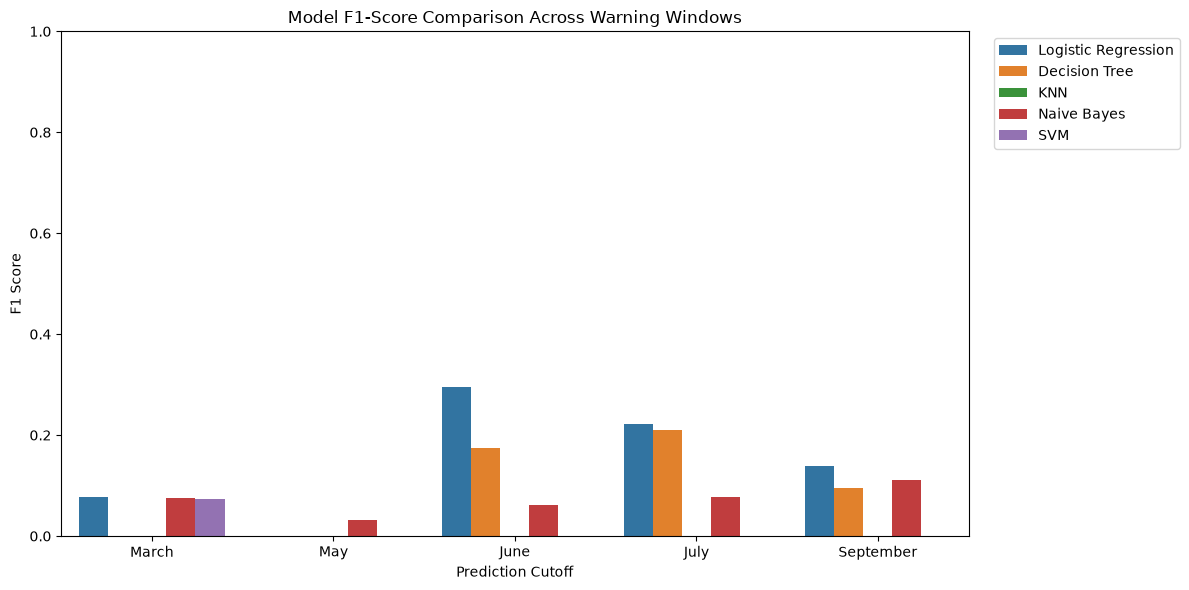

In [160]:
import matplotlib.pyplot as plt
import seaborn as sns

# Compare F1 scores across warning windows
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Warning Window",
    y="F1 Score",
    hue="Model"
)

plt.title("Model F1-Score Comparison Across Warning Windows")
plt.xlabel("Prediction Cutoff")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

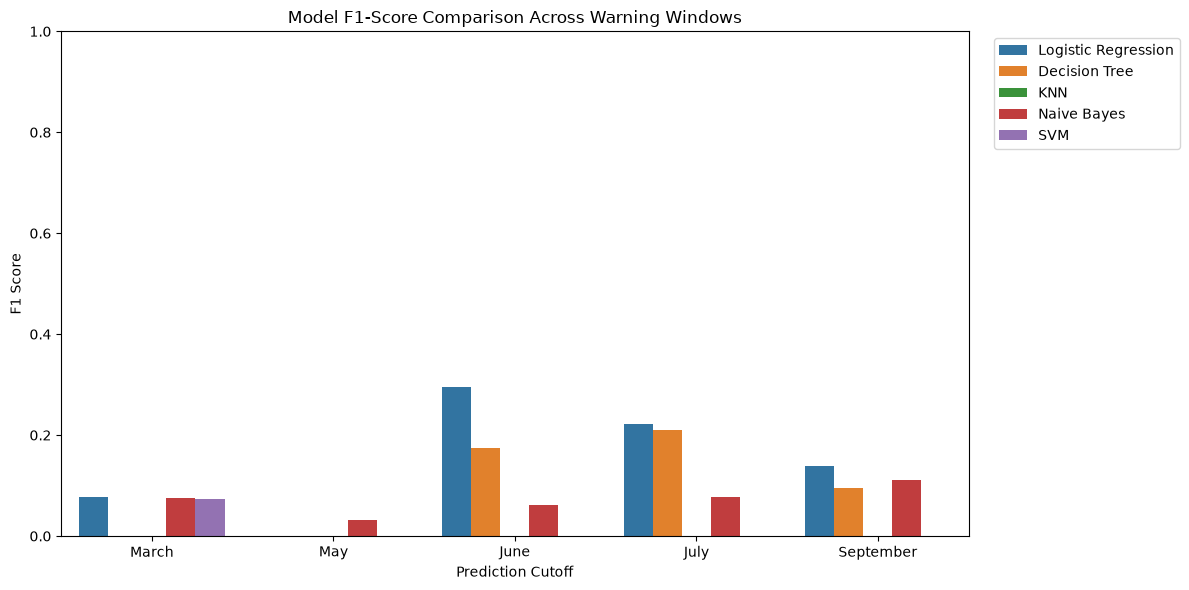

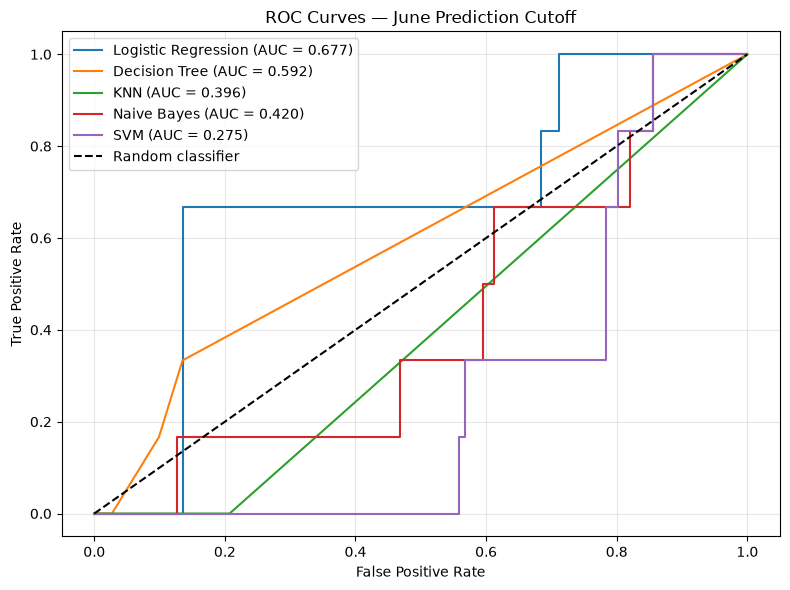

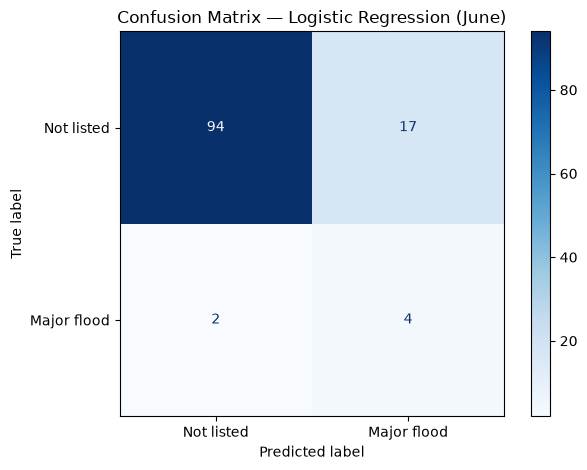

All three figures saved successfully!


In [161]:
from pathlib import Path
from sklearn.metrics import (
    roc_curve,
    auc,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Create figure directory
figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

# Save the F1 comparison graph
plt.figure(figsize=(12, 6))
sns.barplot(
    data=results_df,
    x="Warning Window",
    y="F1 Score",
    hue="Model"
)
plt.title("Model F1-Score Comparison Across Warning Windows")
plt.xlabel("Prediction Cutoff")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(figure_dir / "f1_comparison.png", dpi=300)
plt.show()

# ROC curves for all five classifiers using June rainfall
june_data = oof_predictions_df[
    oof_predictions_df["CUTOFF"] == "June"
]

plt.figure(figsize=(8, 6))

for model_name in models.keys():
    subset = june_data[june_data["MODEL"] == model_name]

    fpr, tpr, roc_thresholds = roc_curve(
        subset["ACTUAL"],
        subset["SCORE"]
    )
    model_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        label=f"{model_name} (AUC = {model_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.title("ROC Curves — June Prediction Cutoff")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(figure_dir / "june_roc_curves.png", dpi=300)
plt.show()

# Confusion matrix for Logistic Regression — June
best_data = june_data[
    june_data["MODEL"] == "Logistic Regression"
]

cm = confusion_matrix(
    best_data["ACTUAL"],
    best_data["PREDICTED"]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not listed", "Major flood"]
).plot(cmap="Blues")

plt.title("Confusion Matrix — Logistic Regression (June)")
plt.tight_layout()
plt.savefig(figure_dir / "june_confusion_matrix.png", dpi=300)
plt.show()

print("All three figures saved successfully!")

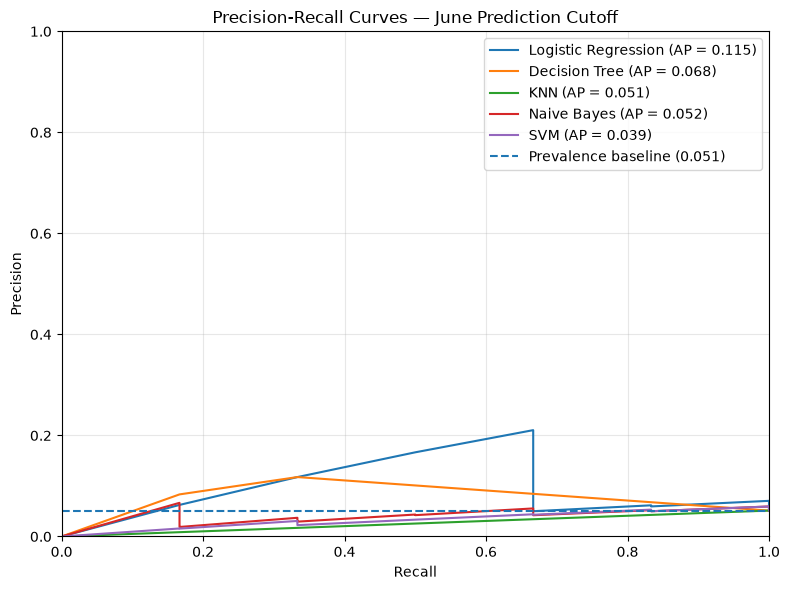

June Precision-Recall figure saved successfully!


In [162]:
# PRECISION-RECALL CURVES: JUNE CUTOFF

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

june_data = oof_predictions_df[
    oof_predictions_df["CUTOFF"] == "June"
]

plt.figure(figsize=(8, 6))

for model_name in models.keys():

    subset = june_data[
        june_data["MODEL"] == model_name
    ]

    precision, recall, pr_thresholds = precision_recall_curve(
        subset["ACTUAL"],
        subset["SCORE"]
    )

    ap = average_precision_score(
        subset["ACTUAL"],
        subset["SCORE"]
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP = {ap:.3f})"
    )

# Random-ranking reference: positive-class prevalence
baseline = y.mean()

plt.axhline(
    baseline,
    linestyle="--",
    label=f"Prevalence baseline ({baseline:.3f})"
)

plt.title("Precision-Recall Curves — June Prediction Cutoff")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figure_dir / "june_precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("June Precision-Recall figure saved successfully!")

#### Results and Discussion

The five classifiers were evaluated across five rainfall prediction windows using stratified three-fold cross-validation.

Logistic Regression using rainfall from January to June achieved the highest Recall (0.667) and F1-score (0.296) among the tested combinations. Logistic Regression using rainfall through September achieved the highest ROC-AUC (0.737).

For the June Logistic Regression configuration, the pooled out-of-fold confusion matrix contained 94 true negatives, 17 false positives, 2 false negatives and 4 true positives.

The findings suggest that June rainfall features provided the most favourable balance of Recall and F1-score in these experiments. However, the small number of documented flood years limits the reliability and generalisability of the results.

The results should therefore be interpreted as exploratory classification findings rather than evidence of a deployable flood-warning system.


####  Descriptive Baseline: Individual Rainfall Measures

As a supplementary sanity check, individual raw rainfall measures are evaluated against the documented flood-year labels using ROC-AUC.

Unlike the cross-validation experiments, this descriptive comparison uses all 117 observations. It is therefore not an independent predictive performance estimate.


In [163]:
# Descriptive rainfall-only baseline comparison

from pathlib import Path
from sklearn.metrics import roc_auc_score

# Individual rainfall measures
baseline_features = {
    "March": "MAR",
    "May": "MAY",
    "June": "JUN",
    "July": "JUL",
    "JJAS": "JJAS",
    "Annual": "ANNUAL"
}

baseline_results = []

# Calculate ROC-AUC for each individual measure
for rainfall_name, column in baseline_features.items():

    score = roc_auc_score(y, df[column])

    baseline_results.append({
        "Rainfall Measure": rainfall_name,
        "Feature": column,
        "ROC-AUC": score
    })

# Display comparison
baseline_auc_df = pd.DataFrame(baseline_results)

display(baseline_auc_df.round(3))

# Save results for reproducibility
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

baseline_auc_df.to_csv(
    output_dir / "rainfall_only_baseline_auc.csv",
    index=False
)

print("Rainfall-only baseline results saved successfully!")

,Rainfall Measure,Feature,ROC-AUC
0,March,MAR,0.432
1,May,MAY,0.607
2,June,JUN,0.851
3,July,JUL,0.782
4,JJAS,JJAS,0.889
5,Annual,ANNUAL,0.848


Rainfall-only baseline results saved successfully!


#### Logistic Regression Performance Across Prediction Cutoffs

This comparison examines how the recall, F1-score and ROC-AUC of Logistic Regression change as additional monthly rainfall observations become available.

The results are obtained from pooled out-of-fold predictions using stratified three-fold cross-validation.

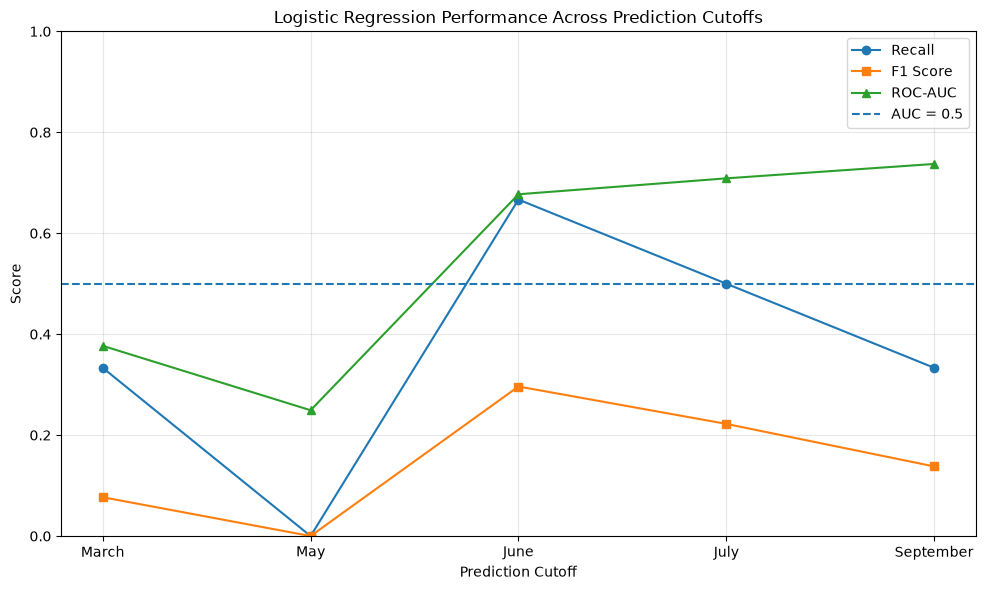

Figure 2 saved successfully!


In [164]:
# Logistic Regression performance across prediction cutoffs

from pathlib import Path
import matplotlib.pyplot as plt

# Define the correct chronological order
cutoff_order = [
    "March", "May", "June", "July", "September"
]

# Filter Logistic Regression results
logistic_results = results_df[
    results_df["Model"] == "Logistic Regression"
].copy()

# Preserve cutoff order
logistic_results["Warning Window"] = pd.Categorical(
    logistic_results["Warning Window"],
    categories=cutoff_order,
    ordered=True
)

logistic_results = logistic_results.sort_values(
    "Warning Window"
)

# Verify that all five cutoffs are present
assert len(logistic_results) == 5, (
    "Expected exactly five Logistic Regression results."
)

# Create the comparison figure
plt.figure(figsize=(10, 6))

cutoffs = logistic_results["Warning Window"].astype(str)

plt.plot(
    cutoffs,
    logistic_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    cutoffs,
    logistic_results["F1 Score"],
    marker="s",
    label="F1 Score"
)

plt.plot(
    cutoffs,
    logistic_results["ROC-AUC"],
    marker="^",
    label="ROC-AUC"
)

# Reference line representing chance-level ROC-AUC
plt.axhline(
    y=0.5,
    linestyle="--",
    label="AUC = 0.5"
)

plt.title(
    "Logistic Regression Performance Across Prediction Cutoffs"
)
plt.xlabel("Prediction Cutoff")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

# Save figure
figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "logistic_cutoff_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 2 saved successfully!")

In [165]:
import math

# June Logistic Regression predictions
best_data = oof_predictions_df[
    (oof_predictions_df["CUTOFF"] == "June") &
    (oof_predictions_df["MODEL"] == "Logistic Regression")
]

# Calculate true positives and false negatives
tp = (
    (best_data["ACTUAL"] == 1) &
    (best_data["PREDICTED"] == 1)
).sum()

fn = (
    (best_data["ACTUAL"] == 1) &
    (best_data["PREDICTED"] == 0)
).sum()

n = tp + fn
p = tp / n

# 95% Wilson confidence interval
z = 1.959963984540054

denominator = 1 + (z ** 2 / n)

centre = (p + z ** 2 / (2 * n)) / denominator

margin = (
    z * math.sqrt(
        p * (1 - p) / n +
        z ** 2 / (4 * n ** 2)
    ) / denominator
)

lower = centre - margin
upper = centre + margin

print("Recall:", round(p, 3))
print("95% Wilson confidence interval:")
print(f"({lower:.2f}, {upper:.2f})")

Recall: 0.667
95% Wilson confidence interval:
(0.30, 0.90)


In [166]:
# Summarise variation in metrics across validation folds

fold_summary = (
    fold_metrics_df
    .groupby(["Warning Window", "Model"])
    .agg(
        Recall_Mean=("Recall", "mean"),
        Recall_Std=("Recall", "std"),
        F1_Mean=("F1 Score", "mean"),
        F1_Std=("F1 Score", "std"),
        AUC_Mean=("ROC-AUC", "mean"),
        AUC_Std=("ROC-AUC", "std"),
        PR_AUC_Mean=("PR-AUC (Average Precision)", "mean"),
        PR_AUC_Std=("PR-AUC (Average Precision)", "std")
    )
    .reset_index()
    .round(3)
)

display(fold_summary)

# Save fold variability summary
fold_summary.to_csv(
    output_dir / "fold_variability_summary.csv",
    index=False
)

print("Fold variability summary:", fold_summary.shape)
print("Saved successfully!")

,Warning Window,Model,Recall_Mean,Recall_Std,F1_Mean,F1_Std,AUC_Mean,AUC_Std,PR_AUC_Mean,PR_AUC_Std
0,July,Decision Tree,0.333,0.289,0.178,0.168,0.617,0.116,0.097,0.050
1,July,KNN,0.000,0.000,0.000,0.000,0.419,0.014,0.051,0.000
2,July,Logistic Regression,0.500,0.500,0.172,0.183,0.766,0.199,0.272,0.155
3,July,Naive Bayes,0.167,0.289,0.056,0.096,0.514,0.304,0.102,0.052
4,July,SVM,0.000,0.000,0.000,0.000,0.437,0.250,0.081,0.033
5,June,Decision Tree,0.333,0.289,0.156,0.145,0.599,0.124,0.086,0.037
6,June,KNN,0.000,0.000,0.000,0.000,0.396,0.016,0.051,0.000
7,June,Logistic Regression,0.667,0.577,0.274,0.286,0.707,0.237,0.202,0.188
8,June,Naive Bayes,0.167,0.289,0.042,0.072,0.459,0.286,0.082,0.033
9,June,SVM,0.000,0.000,0.000,0.000,0.266,0.113,0.053,0.007


Fold variability summary: (25, 10)
Saved successfully!


In [167]:
# CONSOLIDATED PRIMARY MODEL EVALUATION SUMMARY

# Calculate pooled classification metrics from OOF predictions
classification_records = []

for (cutoff, model_name), group in oof_predictions_df.groupby(
    ["CUTOFF", "MODEL"],
    sort=False
):

    y_true = group["ACTUAL"]
    y_pred = group["PREDICTED"]

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    classification_records.append({

        "Warning Window": cutoff,
        "Model": model_name,

        "Pooled_OOF_Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "Pooled_OOF_Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "Pooled_OOF_F1": f1_score(
            y_true, y_pred, zero_division=0
        ),

        "TP": int(tp),
        "FN": int(fn),
        "FP": int(fp),
        "TN": int(tn)
    })

classification_summary_df = pd.DataFrame(
    classification_records
)

# Prepare fold-level variability metrics
fold_summary_for_merge = fold_summary.rename(
    columns={
        "Recall_Mean": "Fold_Recall_Mean",
        "Recall_Std": "Fold_Recall_Std",
        "F1_Mean": "Fold_F1_Mean",
        "F1_Std": "Fold_F1_Std",
        "AUC_Mean": "Fold_ROC_AUC_Mean",
        "AUC_Std": "Fold_ROC_AUC_Std",
        "PR_AUC_Mean": "Fold_PR_AUC_Mean",
        "PR_AUC_Std": "Fold_PR_AUC_Std"
    }
)

# Preserve pooled ranking metrics for comparison only
pooled_ranking_reference = results_df[[
    "Warning Window",
    "Model",
    "ROC-AUC",
    "PR-AUC (Average Precision)"
]].rename(
    columns={
        "ROC-AUC": "Pooled_ROC_AUC_Reference",
        "PR-AUC (Average Precision)": "Pooled_PR_AUC_Reference"
    }
)

# Combine classification and fold-level ranking metrics
primary_model_evaluation_df = (
    classification_summary_df
    .merge(
        fold_summary_for_merge,
        on=["Warning Window", "Model"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        pooled_ranking_reference,
        on=["Warning Window", "Model"],
        how="left",
        validate="one_to_one"
    )
)

# Validate final evaluation summary
assert len(primary_model_evaluation_df) == 25

assert primary_model_evaluation_df[
    "Model"
].nunique() == 5

assert primary_model_evaluation_df[
    "Warning Window"
].nunique() == 5

assert primary_model_evaluation_df[
    "Fold_ROC_AUC_Mean"
].notna().all()

assert primary_model_evaluation_df[
    "Fold_PR_AUC_Mean"
].notna().all()

# Round metrics for presentation
primary_model_evaluation_df = (
    primary_model_evaluation_df.round(3)
)

# Display results
display(
    primary_model_evaluation_df.sort_values(
        ["Warning Window", "Model"]
    )
)

# Save consolidated evaluation results
primary_model_evaluation_df.to_csv(
    output_dir / "primary_model_evaluation_summary.csv",
    index=False
)

print("\nPrimary evaluation summary generated!")
print("Model-cutoff combinations:", len(primary_model_evaluation_df))
print("Models:", primary_model_evaluation_df["Model"].nunique())
print("Cutoffs:", primary_model_evaluation_df["Warning Window"].nunique())
print("Saved primary model evaluation summary successfully!")

,Warning Window,Model,Pooled_OOF_Recall,Pooled_OOF_Precision,Pooled_OOF_F1,TP,FN,FP,TN,Fold_Recall_Mean,Fold_Recall_Std,Fold_F1_Mean,Fold_F1_Std,Fold_ROC_AUC_Mean,Fold_ROC_AUC_Std,Fold_PR_AUC_Mean,Fold_PR_AUC_Std,Pooled_ROC_AUC_Reference,Pooled_PR_AUC_Reference
16,July,Decision Tree,0.333,0.154,0.211,2,4,11,100,0.333,0.289,0.178,0.168,0.617,0.116,0.097,0.050,0.613,0.078
17,July,KNN,0.000,0.000,0.000,0,6,9,102,0.000,0.000,0.000,0.000,0.419,0.014,0.051,0.000,0.419,0.051
15,July,Logistic Regression,0.500,0.143,0.222,3,3,18,93,0.500,0.500,0.172,0.183,0.766,0.199,0.272,0.155,0.709,0.247
18,July,Naive Bayes,0.167,0.050,0.077,1,5,19,92,0.167,0.289,0.056,0.096,0.514,0.304,0.102,0.052,0.476,0.064
19,July,SVM,0.000,0.000,0.000,0,6,7,104,0.000,0.000,0.000,0.000,0.437,0.250,0.081,0.033,0.446,0.057
11,June,Decision Tree,0.333,0.118,0.174,2,4,15,96,0.333,0.289,0.156,0.145,0.599,0.124,0.086,0.037,0.592,0.068
12,June,KNN,0.000,0.000,0.000,0,6,13,98,0.000,0.000,0.000,0.000,0.396,0.016,0.051,0.000,0.396,0.051
10,June,Logistic Regression,0.667,0.190,0.296,4,2,17,94,0.667,0.577,0.274,0.286,0.707,0.237,0.202,0.188,0.677,0.115
13,June,Naive Bayes,0.167,0.038,0.062,1,5,25,86,0.167,0.289,0.042,0.072,0.459,0.286,0.082,0.033,0.420,0.052
14,June,SVM,0.000,0.000,0.000,0,6,10,101,0.000,0.000,0.000,0.000,0.266,0.113,0.053,0.007,0.275,0.039



Primary evaluation summary generated!
Model-cutoff combinations: 25
Models: 5
Cutoffs: 5
Saved primary model evaluation summary successfully!


In [168]:
# Verify regenerated OOF prediction file

saved_oof = pd.read_csv(
    "../data/processed/oof_predictions.csv"
)

assert saved_oof.shape == (2925, 7)

assert "SCORE" in saved_oof.columns
assert "PROBABILITY" not in saved_oof.columns

assert saved_oof["SCORE"].notna().all()

assert saved_oof["MODEL"].nunique() == 5
assert saved_oof["CUTOFF"].nunique() == 5

print("OOF prediction validation passed!")
print("Shape:", saved_oof.shape)
print("Columns:", saved_oof.columns.tolist())

OOF prediction validation passed!
Shape: (2925, 7)
Columns: ['YEAR', 'CUTOFF', 'MODEL', 'FOLD', 'ACTUAL', 'PREDICTED', 'SCORE']


### Threshold Sensitivity Across Prediction Cutoffs

This visualisation compares fold-level F1-score across the five predefined classification thresholds for class-weighted Logistic Regression and RandomOverSampler Logistic Regression.

Error bars represent the standard deviation across the three validation folds.

The comparison helps examine how classification performance changes with different decision thresholds and whether the observed patterns remain consistent across validation folds.

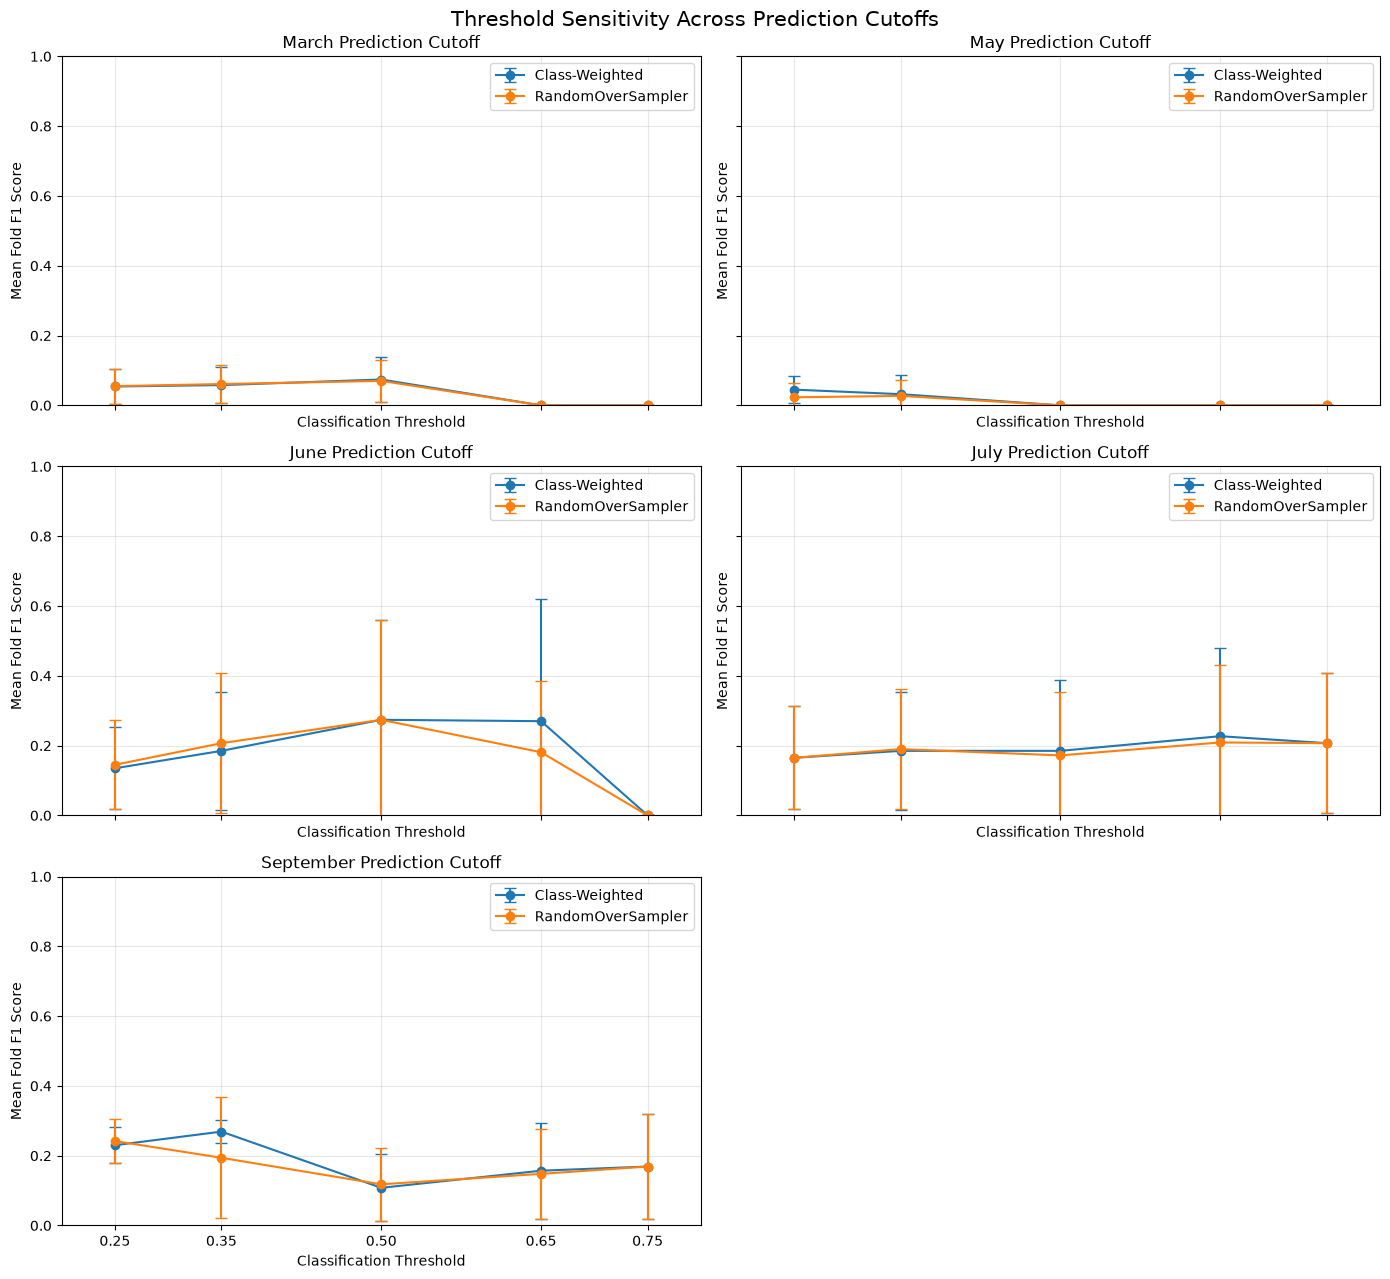

Threshold sensitivity figure saved successfully!


In [169]:
# THRESHOLD SENSITIVITY VISUALISATION
# Fold-Level F1 Score Comparison

import matplotlib.pyplot as plt
from pathlib import Path

threshold_values = [0.25, 0.35, 0.50, 0.65, 0.75]

cutoff_order = [
    "March", "May", "June", "July", "September"
]

approach_order = [
    "Class-Weighted",
    "RandomOverSampler"
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 13),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for index, cutoff in enumerate(cutoff_order):

    ax = axes[index]

    for approach in approach_order:

        subset = threshold_results_df[
            (threshold_results_df["Warning Window"] == cutoff) &
            (threshold_results_df["Approach"] == approach)
        ].sort_values("Threshold")

        ax.errorbar(
            subset["Threshold"],
            subset["F1_Mean"],
            yerr=subset["F1_Std"],
            marker="o",
            capsize=4,
            linewidth=1.5,
            label=approach
        )

    ax.set_title(f"{cutoff} Prediction Cutoff")
    ax.set_xlabel("Classification Threshold")
    ax.set_ylabel("Mean Fold F1 Score")

    # Explicitly set the five intended threshold positions
    ax.set_xticks(threshold_values)
    ax.set_xticklabels(
        [f"{value:.2f}" for value in threshold_values]
    )

    ax.set_xlim(0.20, 0.80)
    ax.set_ylim(0, 1)

    ax.grid(alpha=0.3)
    ax.legend()

# Hide unused subplot
axes[-1].axis("off")

fig.suptitle(
    "Threshold Sensitivity Across Prediction Cutoffs",
    fontsize=15
)

plt.tight_layout()

figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "threshold_sensitivity_fold_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Threshold sensitivity figure saved successfully!")

#### Observations: Threshold Sensitivity Analysis

The threshold sensitivity analysis demonstrates that classification performance varies across prediction cutoffs and imbalance-handling approaches.

For the June prediction cutoff, both class-weighted Logistic Regression and RandomOverSampler Logistic Regression achieve their highest mean fold F1-score around the 0.50 threshold.

For July, class-weighted Logistic Regression achieves its highest mean fold F1-score at the 0.65 threshold, although the difference between the two approaches remains relatively small.

For September, class-weighted Logistic Regression performs better at the 0.35 threshold, while RandomOverSampler Logistic Regression achieves its highest mean fold F1-score at 0.25.

March and May exhibit consistently low F1-scores across the evaluated thresholds, indicating limited classification performance during the earlier prediction windows.

The error bars indicate considerable variability across validation folds, particularly for June and September. This variability is expected to be sensitive to the small number of documented flood-year observations.

Overall, the analysis illustrates the trade-off between recall and precision when changing classification thresholds. The results are exploratory sensitivity comparisons and do not establish an independently validated optimal operating threshold.